# Question 2. 1D Convolutional Neural Network

## Imports

In [30]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from tensorflow import keras
from tensorflow.keras import layers

import matplotlib.pyplot as plt

import numpy as np

## a) Load Data

This question uses the Iris dataset.
- 150 observations.
- 4 numeric tabular features with no spatial or time order. 
- 3 flower classes.

In [2]:
iris = load_iris()

In [4]:
# display the first five rows as table using head () with feature names and target labels
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['target'] = pd.Categorical.from_codes(iris.target, iris.target_names)
display(df.head())

# check for missing values
print(df.isnull().sum().sum())

# report class counts using table
display(df['target'].value_counts().to_frame('count'))

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


0


,count
target,
setosa,50
versicolor,50
virginica,50


Next we split the data into fitting, validation, and testing portions. First we split the training and testing data. `stratify=iris.target` keeps the class propotions the same in both sets.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.2, stratify=iris.target, random_state=42)

Next we split the training data into fitting and validation data.

In [7]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

In [8]:
# report the sizes and class counts for all three sets
sizes = pd.DataFrame({
    name: pd.Series(y).map(dict(enumerate(iris.target_names))).value_counts()
    for name, y in [('fit', y_fit), ('validation', y_val), ('test', y_test)]
}).T
sizes['total'] = sizes.sum(axis=1)
display(sizes)

,setosa,versicolor,virginica,total
fit,32,32,32,96
validation,8,8,8,24
test,10,10,10,30


Next we scale the data.

StandardScaler rescales each feature so it has a mean of 0 and standard deviation of 1. For every column it computes `(x - mean) / std`. Without scaling, a feature with large values can outweigh one with small values. 
- `fit` learn each column's mean and standard deviation.
- `transform` applies `(x - mean) / std` using those learned numbers.

We fit StandardScaer on the fitting features only. Then, we use that information to transform the validation and test features. 

Splitting before fitting leaks information because if we fit the scalar on the full dataset, the mean and standard deviation includes the validation and test rows. This means that information about the validation and testing data ends up in the transformed training features. This leads the model to be influenced by the training and validation data. 

In [10]:

scaler = StandardScaler()
X_fit_s = scaler.fit_transform(X_fit)   # learn mean/std from the fitting set only, then scale it
X_val_s = scaler.transform(X_val)       # scale validation using the fitting set's mean/std
X_test_s = scaler.transform(X_test)     # scale test using the fitting set's mean/std

## b) Reshape the Data

The extra dimension treats each flower's 4 features as a sequence of 4 time steps with 1 channel each. Flattening turns an image like `(28, 28)` into one vector `(784,)`. This looses the information about which values sit next to each other.

A Conv1D or RNN layer requires a 3D input of `(samples, steps, channels)`. The reshape preserves the information about values' relative positions, and creates the proper number of dimensions needed for these layers. 

For the Iris dataset, the features don't have a natural order like pixels or timesteps would. So the reshape is mostly for meeting the input format requirement for a Conv1D layer.

In [11]:
# reshape the scaled feature matrix from (samples, 4) to (samples, 4, 1)
X_fit_r = X_fit_s.reshape(-1, 4, 1)
X_val_r = X_val_s.reshape(-1, 4, 1)
X_test_r = X_test_s.reshape(-1, 4, 1)

# display new fitting validation and test shapes
print("fit:", X_fit_r.shape)
print("validation:", X_val_r.shape)
print("test:", X_test_r.shape)

fit: (96, 4, 1)
validation: (24, 4, 1)
test: (30, 4, 1)


## c) Sequential Model

`Conv1D(32, ...)` learns 32 separate filters, so it outputs 32 feature maps. 
- `kernel_size=3`: Each filter looks at 3 neighboring steps at a time.
- `strides=1`: The window moves 1 step at a time.

In [14]:
def build_sequential_model():
    model = keras.Sequential([
        keras.Input(shape=(4, 1)),
        layers.Conv1D(32, kernel_size=3, strides=1, padding='valid', activation='relu'),
        layers.MaxPooling1D(pool_size=2),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(3, activation='softmax'),
    ])
    return model

In [15]:
model = build_sequential_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 2, 32)          │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 1, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,435 (9.51 KB)

 Trainable params: 2,435 (9.51 KB)

 Non-trainable params: 0 (0.00 B)

## d) Train Sequential Model

In [21]:
def train_sequential_model(model, X_val_r, y_val):

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )

    history = model.fit(
        X_fit_r, y_fit,
        epochs=10,
        batch_size=8,
        shuffle=True,
        validation_data=(X_val_r, y_val),
    )
    return history

In [23]:
# reset seeds to 42 before building the model
keras.utils.set_random_seed(42)   # sets Python, NumPy and TensorFlow seeds together
model = build_sequential_model()
history = train_sequential_model(model, X_val_r, y_val)

Epoch 1/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.6354 - loss: 0.9685 - val_accuracy: 0.6667 - val_loss: 0.8723
Epoch 2/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7292 - loss: 0.8295 - val_accuracy: 0.7917 - val_loss: 0.7481
Epoch 3/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8229 - loss: 0.7150 - val_accuracy: 0.7917 - val_loss: 0.6446
Epoch 4/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8542 - loss: 0.6163 - val_accuracy: 0.7917 - val_loss: 0.5632
Epoch 5/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8333 - loss: 0.5362 - val_accuracy: 0.7917 - val_loss: 0.5030
Epoch 6/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8333 - loss: 0.4748 - val_accuracy: 0.7917 - val_loss: 0.4609
Epoch 7/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8333 - loss: 0.4288 - val_accuracy: 0.7917 - val_loss: 0.4314
Epoch 8/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.8542 - loss: 0.3931 - val_accuracy: 0.7917 - v

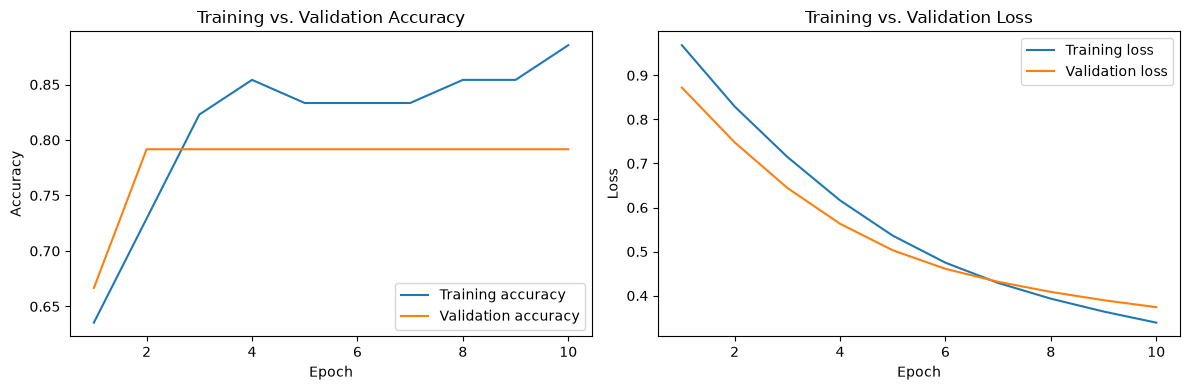

In [24]:
h = history.history
epochs = range(1, len(h['accuracy']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# accuracy
ax1.plot(epochs, h['accuracy'], label='Training accuracy')
ax1.plot(epochs, h['val_accuracy'], label='Validation accuracy')
ax1.set_title('Training vs. Validation Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()

# loss
ax2.plot(epochs, h['loss'], label='Training loss')
ax2.plot(epochs, h['val_loss'], label='Validation loss')
ax2.set_title('Training vs. Validation Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()

plt.tight_layout()
plt.show()


## e) Evaluate the Sequential Model

In [26]:
def test_sequential_model(model, X_test_r, y_test):
    # evaluate model on untouched test set
    test_loss, test_acc = model.evaluate(X_test_r, y_test, verbose=0)
    print(f"Test loss: {test_loss:.4f}")
    print(f"Test accuracy: {test_acc:.4f}")
    return test_loss, test_acc

In [29]:
# call test_sequential_model function
test_loss, test_acc = test_sequential_model(model, X_test_r, y_test)

# report test loss, test accuracy, and the number of correctly classified observations out of the total test observations
y_pred = np.argmax(model.predict(X_test_r, verbose=0), axis=1)
n_correct = int((y_pred == y_test).sum())
print(f"Correctly classified: {n_correct} / {len(y_test)}")

Test loss: 0.3816
Test accuracy: 0.7667
Correctly classified: 23 / 30


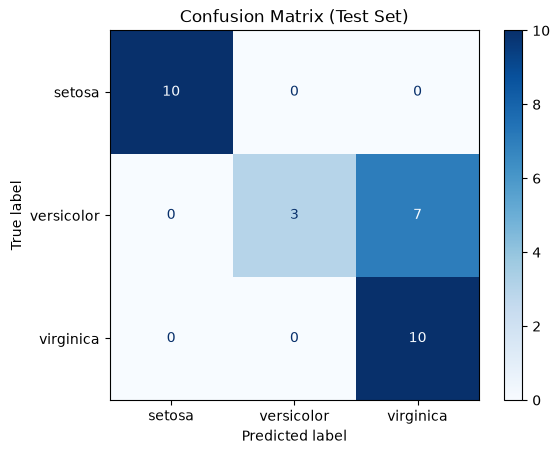

In [31]:
# plot the confusion matrix labeled with the three flower class names
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix (Test Set)')
plt.show()

### Interpretation of Results

Training Curves: Both losses are still falling at epoch 10, with training and validation loss close togther. This indicated underfitting. The model hasn't converged yet. The predicitons on the validation set stop improving even though the model accuracy is still increasing, because the model is still improving its confidence on the same predictions. 

Test Results: Test accuracy is consistent with the validation accuracy, so the models generalizes as well as it fits.

The confusion matrix shows that the Setosa class is easy to separate from the other. Mix-ups between Versicolor and Virginica are common. 

These results do not necessarily show the model is bad, just that is is undertrained.